In [2]:
import pandas as pd
df = pd.read_csv("credit_card_customers.csv")

In [6]:
# Create tenure buckets
df['tenure_bucket'] = pd.cut(
    df['tenure_months'],
    bins=[0, 6, 12, 24, 48, 200],
    labels=[
        '<6 months',
        '6–12 months',
        '12–24 months',
        '24–48 months',
        '48+ months'
    ],
    right=False
)

In [8]:
# Utilization buckets
df['util_bucket'] = pd.cut(
    df['utilization_ratio'],
    bins=[0, 0.3, 0.6, 0.9, 1.1],
    labels=[
        '≤30% (Healthy)',
        '30–60%',
        '60–90%',
        '>90% (Critical)'
    ],
    right=False
)

In [10]:
# Transaction activity buckets
df['tx_bucket'] = pd.cut(
    df['monthly_transactions'],
    bins=[0, 10, 30, 60, 200],
    labels=[
        'Low',
        'Medium',
        'High',
        'Very High'
    ],
    right=False
)

In [12]:
tenure_churn = df.groupby('tenure_bucket')['churned'].mean() * 100
tenure_churn

/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_50109/3444458392.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tenure_churn = df.groupby('tenure_bucket')['churned'].mean() * 100


tenure_bucket
<6 months        1.851852
6–12 months     12.676056
12–24 months     4.294479
24–48 months     4.361371
48+ months       2.244669
Name: churned, dtype: float64

/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_50109/867647106.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tenure_churn = df.groupby('tenure_bucket')['churned'].mean() * 100


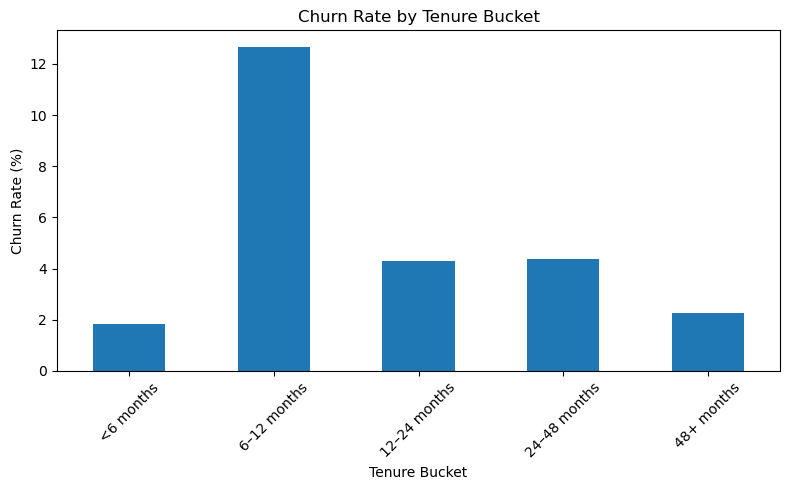

In [14]:
import matplotlib.pyplot as plt

# Churn rate by tenure bucket
tenure_churn = df.groupby('tenure_bucket')['churned'].mean() * 100

plt.figure(figsize=(8,5))
tenure_churn.plot(kind='bar')
plt.title('Churn Rate by Tenure Bucket')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Tenure Bucket')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('churn_by_tenure.png')
plt.show()

/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_50109/3470132924.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  util_churn = df.groupby('util_bucket')['churned'].mean() * 100


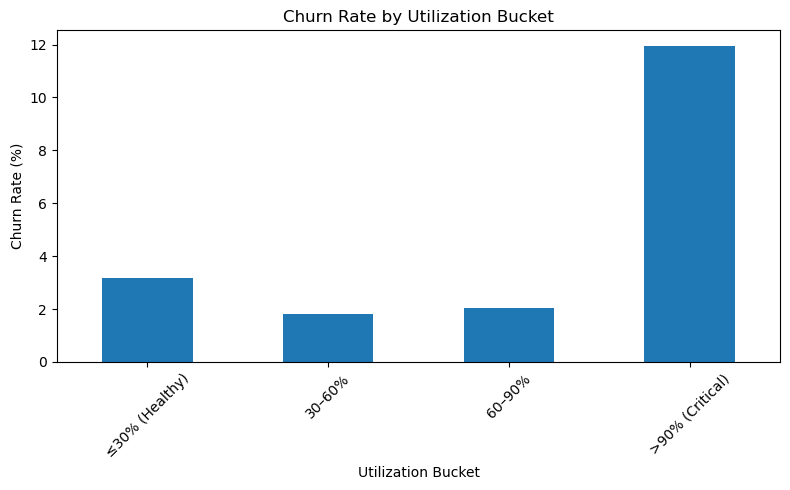

In [16]:
# Churn rate by utilization bucket
util_churn = df.groupby('util_bucket')['churned'].mean() * 100

plt.figure(figsize=(8,5))
util_churn.plot(kind='bar')
plt.title('Churn Rate by Utilization Bucket')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Utilization Bucket')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('churn_by_utilization.png')
plt.show()

/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_50109/2728885237.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tx_churn = df.groupby('tx_bucket')['churned'].mean() * 100


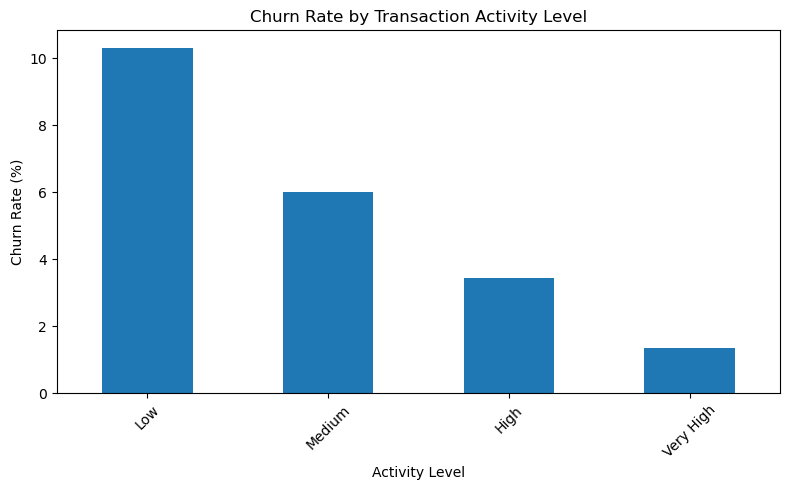

In [18]:
tx_churn = df.groupby('tx_bucket')['churned'].mean() * 100

plt.figure(figsize=(8,5))
tx_churn.plot(kind='bar')
plt.title('Churn Rate by Transaction Activity Level')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Activity Level')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('churn_by_activity.png')
plt.show()

/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_50109/2297467670.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = df.pivot_table(


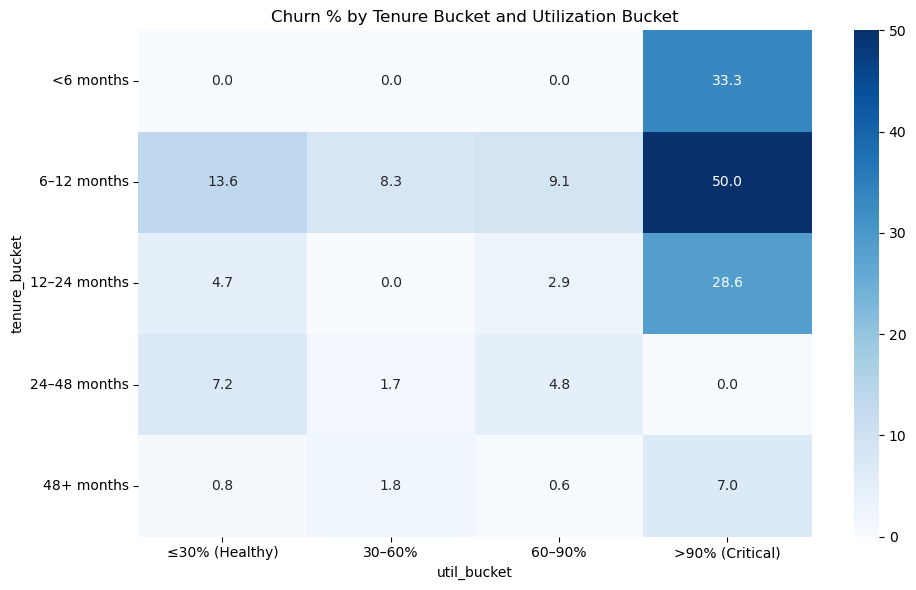

In [20]:
import seaborn as sns

# Pivot table for heatmap
heatmap_data = df.pivot_table(
    values='churned',
    index='tenure_bucket',
    columns='util_bucket',
    aggfunc='mean'
) * 100

plt.figure(figsize=(10,6))
sns.heatmap(heatmap_data, annot=True, cmap='Blues', fmt=".1f")
plt.title('Churn % by Tenure Bucket and Utilization Bucket')
plt.tight_layout()
plt.savefig('churn_heatmap.png')
plt.show()

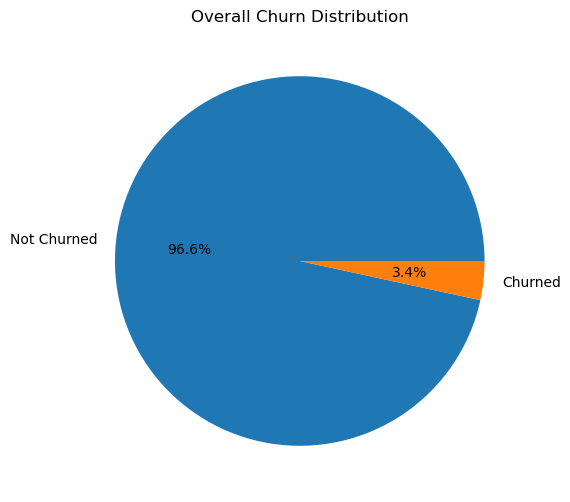

In [22]:
churn_counts = df['churned'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(churn_counts, labels=['Not Churned','Churned'], autopct='%1.1f%%')
plt.title('Overall Churn Distribution')
plt.savefig('churn_pie.png')
plt.show()

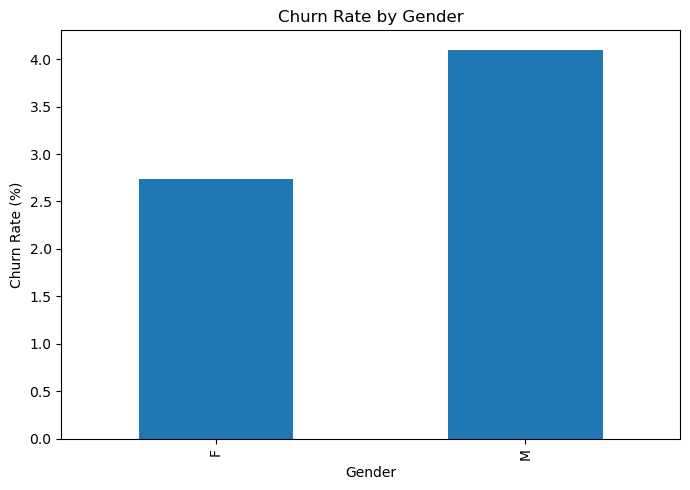

In [24]:
gender_churn = df.groupby('gender')['churned'].mean() * 100

plt.figure(figsize=(7,5))
gender_churn.plot(kind='bar')
plt.title('Churn Rate by Gender')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Gender')
plt.tight_layout()
plt.savefig('churn_by_gender.png')
plt.show()

/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_50109/2125010835.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tenure_churn = df.groupby('tenure_bucket')['churned'].mean()


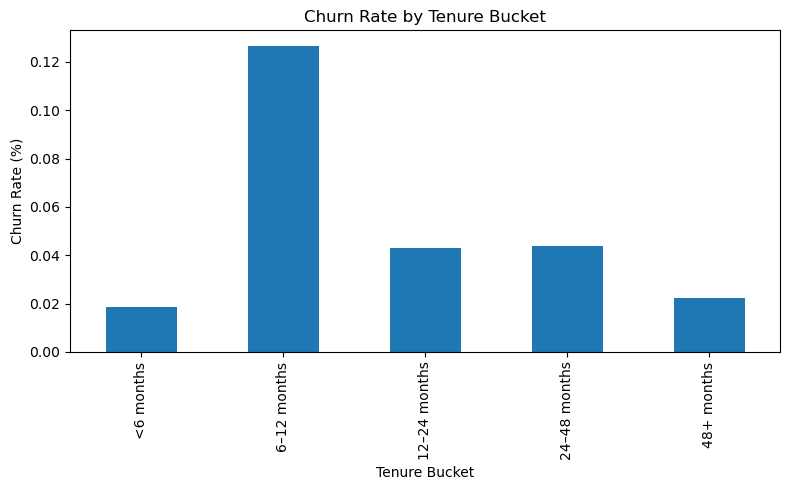

/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_50109/1406014785.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tenure_churn = df.groupby('tenure_bucket')['churned'].mean() * 100


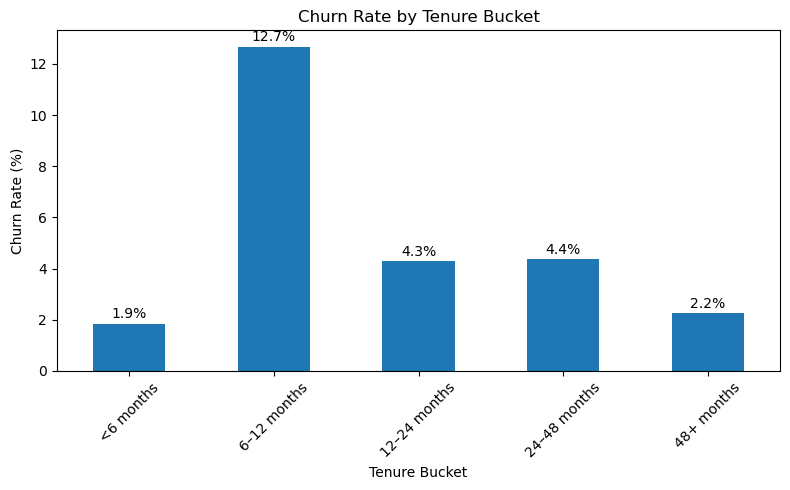

In [28]:
import matplotlib.pyplot as plt

# Calculate churn (%) for each tenure bucket
tenure_churn = df.groupby('tenure_bucket')['churned'].mean() * 100  

plt.figure(figsize=(8,5))
plot = tenure_churn.plot(kind='bar')

plt.title('Churn Rate by Tenure Bucket')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Tenure Bucket')
plt.xticks(rotation=45)

# Add value labels above bars
for i, value in enumerate(tenure_churn):
    plt.text(i, value + 0.2, f"{value:.1f}%", ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('churn_by_tenure.png')
plt.show()

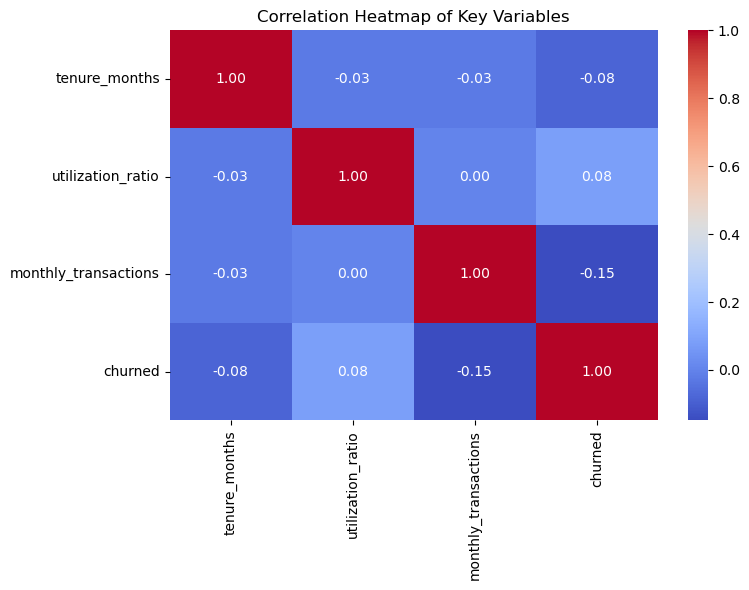

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = ['tenure_months', 'utilization_ratio', 'monthly_transactions', 'churned']

plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Key Variables")
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# select features
X = df[['tenure_months', 'utilization_ratio', 'monthly_transactions']]
y = df['churned']

# split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# train model
model = LogisticRegression()
model.fit(X_train, y_train)

# predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98       291
           1       0.00      0.00      0.00         9

    accuracy                           0.97       300
   macro avg       0.48      0.50      0.49       300
weighted avg       0.94      0.97      0.96       300

ROC-AUC Score: 0.7525773195876289


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [39]:
import pandas as pd

importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print(importance)

                Feature  Coefficient
1     utilization_ratio     0.707118
0         tenure_months    -0.016367
2  monthly_transactions    -0.029389


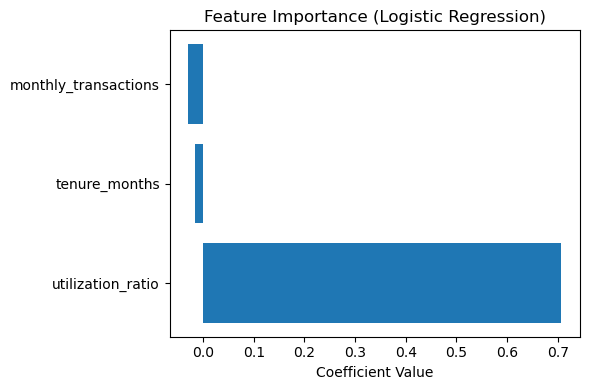

In [41]:
plt.figure(figsize=(6,4))
plt.barh(importance['Feature'], importance['Coefficient'])
plt.title("Feature Importance (Logistic Regression)")
plt.xlabel("Coefficient Value")
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()

In [43]:
df['churn_probability'] = model.predict_proba(df[X.columns])[:,1]

top_risk = df[['customer_id', 'churn_probability']].sort_values(
    by='churn_probability', 
    ascending=False
).head(10)

top_risk

,customer_id,churn_probability
1091,101091,0.378345
190,100190,0.341637
888,100888,0.313780
1268,101268,0.298774
1002,101002,0.290767
931,100931,0.275420
1346,101346,0.269690
199,100199,0.264157
927,100927,0.253379
1460,101460,0.247085


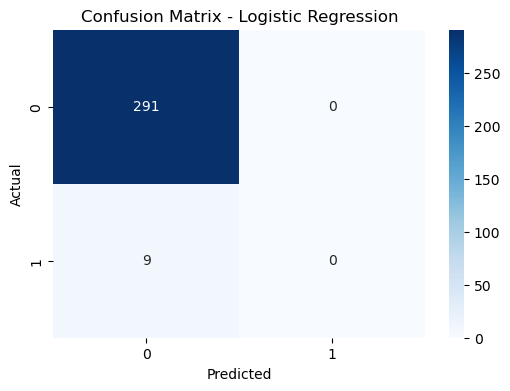

In [45]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig('confusion_matrix.png')
plt.show()

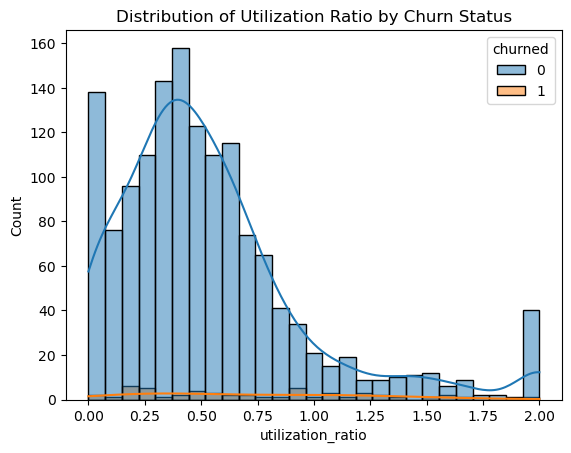

In [47]:
sns.histplot(data=df, x='utilization_ratio', hue='churned', kde=True)
plt.title("Distribution of Utilization Ratio by Churn Status")
plt.savefig('utilization_distribution.png')
plt.show()

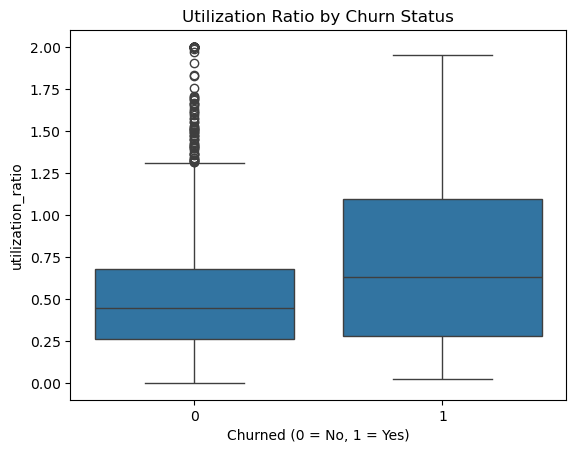

In [49]:
sns.boxplot(data=df, x='churned', y='utilization_ratio')
plt.title("Utilization Ratio by Churn Status")
plt.xlabel("Churned (0 = No, 1 = Yes)")
plt.savefig('utilization_boxplot.png')
plt.show()

In [51]:
df.to_csv("credit_card_customers_clean.csv", index=False)

In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve


In [3]:
# Load cleaned dataset
df = pd.read_csv("credit_card_customers_clean.csv")

# Preview data
print(df.head())

# Check columns
print(df.columns)


   customer_id  age gender           city  tenure_months  annual_income_usd  \
0       100000   23      M   Hartford, CT             93              54209   
1       100001   62      F     Boston, MA             80              61463   
2       100002   55      F    Buffalo, NY            111              66816   
3       100003   43      F   Hartford, CT            115              77096   
4       100004   42      M  Rochester, NY             84              86617   

   credit_score  card_limit_usd  current_balance_usd  utilization_ratio  \
0           676            5644              4055.16              0.718   
1           618           13205              2447.67              0.185   
2           628            4025              1441.39              0.358   
3           625           12846               885.96              0.069   
4           717            4950                 0.00              0.000   

   monthly_transactions  avg_transaction_value_usd  late_fee_count_12m  \


In [9]:
# Target variable
y = df["churned"]

# Feature variables (remove target and unnecessary columns)
X = df.drop(columns=["churned"])
# Convert categorical variables to numeric
X = pd.get_dummies(X, drop_first=True)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
